# Análise exploratória — tempo de entrega

Base: [Food Delivery Dataset](https://www.kaggle.com/datasets/gauravmalik26/food-delivery-dataset) (`train.csv`, 45.593 pedidos). Dicionário de colunas e problemas conhecidos em [`data/README.md`](../data/README.md).

**Objetivos:** definir a limpeza necessária, identificar as variáveis com maior relação com o tempo de entrega e mapear riscos de vazamento antes da modelagem.

## 1. Carregamento

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from project_nov26_p1_eta.data import clean
from project_nov26_p1_eta.features import haversine_km

plt.rcParams.update(
    {"figure.figsize": (7, 4), "axes.spines.top": False, "axes.spines.right": False}
)
TARGET = "Time_taken(min)"

df = pd.read_csv("../data/raw/train.csv")
print(df.shape)
df.head()

(45593, 20)


,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
0,0x4607,INDORES13DEL02,37,4.9,22.745049,75.892471,22.765049,75.912471,19-03-2022,11:30:00,11:45:00,conditions Sunny,High,2,Snack,motorcycle,0,No,Urban,(min) 24
1,0xb379,BANGRES18DEL02,34,4.5,12.913041,77.683237,13.043041,77.813237,25-03-2022,19:45:00,19:50:00,conditions Stormy,Jam,2,Snack,scooter,1,No,Metropolitian,(min) 33
2,0x5d6d,BANGRES19DEL01,23,4.4,12.914264,77.678400,12.924264,77.688400,19-03-2022,08:30:00,08:45:00,conditions Sandstorms,Low,0,Drinks,motorcycle,1,No,Urban,(min) 26
3,0x7a6a,COIMBRES13DEL02,38,4.7,11.003669,76.976494,11.053669,77.026494,05-04-2022,18:00:00,18:10:00,conditions Sunny,Medium,0,Buffet,motorcycle,1,No,Metropolitian,(min) 21
4,0x70a2,CHENRES12DEL01,32,4.6,12.972793,80.249982,13.012793,80.289982,26-03-2022,13:30:00,13:45:00,conditions Cloudy,High,1,Snack,scooter,1,No,Metropolitian,(min) 30


## 2. Diagnóstico de qualidade

In [2]:
textos = [c for c in df.columns if df[c].dtype == "str"]
diagnostico = (
    pd.DataFrame(
        {
            "nulos_reais": df.isna().sum(),
            "texto_NaN": {c: df[c].str.strip().eq("NaN").sum() for c in textos},
            "espaco_no_fim": {c: df[c].str.endswith(" ").sum() for c in textos},
        }
    )
    .fillna(0)
    .astype(int)
)
diagnostico[diagnostico.sum(axis=1) > 0]

,nulos_reais,texto_NaN,espaco_no_fim
City,0,1200,45593
Delivery_person_Age,0,1854,1854
Delivery_person_ID,0,0,45593
Delivery_person_Ratings,0,1908,1908
Festival,0,228,45593
ID,0,0,45593
Road_traffic_density,0,601,45593
Time_Orderd,0,1731,1731
Type_of_order,0,0,45593
Type_of_vehicle,0,0,45593


In [3]:
df[["Weatherconditions", TARGET, "Delivery_person_Ratings"]].head(3)

,Weatherconditions,Time_taken(min),Delivery_person_Ratings
0,conditions Sunny,(min) 24,4.9
1,conditions Stormy,(min) 33,4.5
2,conditions Sandstorms,(min) 26,4.4


**Observações**
- `isna()` não encontra nenhum ausente, mas há milhares de valores `"NaN "`: os ausentes estão **codificados como texto**, e por isso idade, nota e `multiple_deliveries` foram lidas como texto.
- Quase todos os textos têm espaço residual no fim (`"High "`, `"Snack "`).
- O alvo vem como `"(min) 24"` e o clima com o prefixo `"conditions "`.

In [4]:
pd.DataFrame(
    {
        "lat_restaurante_negativa": [(df["Restaurant_latitude"] < 0).sum()],
        "coord_restaurante_~0": [(df["Restaurant_latitude"].abs() < 1).sum()],
        "coord_entrega_~0": [(df["Delivery_location_latitude"] < 1).sum()],
        "nota_>5": [
            (pd.to_numeric(df["Delivery_person_Ratings"].str.strip(), errors="coerce") > 5).sum()
        ],
        "IDs_duplicados": [df["ID"].duplicated().sum()],
    }
)

,lat_restaurante_negativa,coord_restaurante_~0,coord_entrega_~0,nota_>5,IDs_duplicados
0,431,3640,3640,53,0


## 3. Limpeza

Regras implementadas em [`data.clean`](../src/project_nov26_p1_eta/data.py), reaproveitadas pelo treino e pela API:

| Problema | Tratamento | Motivo |
|---|---|---|
| Espaços residuais | `str.strip()` em todas as colunas de texto | `"Snack "` e `"Snack"` seriam categorias diferentes |
| `"NaN"` como texto | prefixo do clima removido **antes**; depois `"NaN"` → `np.nan` | só `np.nan` é reconhecido como ausente pelo pandas, scikit-learn e LightGBM |
| Alvo `"(min) 24"` | extração dos dígitos → inteiro | — |
| Nota > 5 | → ausente | fora da escala 1–5 |
| Latitude/longitude negativa do restaurante | valor absoluto | todas as cidades ficam no hemisfério norte, a leste de Greenwich: é sinal invertido |
| Coordenada ≈ 0 | → ausente (a linha é mantida) | perde-se só a distância daquele pedido, não o pedido inteiro |

A imputação **não** é feita aqui: ela fica no pipeline de modelagem, ajustada apenas nos dados de treino, para evitar vazamento entre treino e teste.

In [5]:
dfc = clean(df)

# Validação
assert not any(dfc[c].str.endswith(" ").any() for c in dfc.columns if dfc[c].dtype == "str")
assert not any(dfc[c].eq("NaN").any() for c in dfc.columns if dfc[c].dtype == "str")
assert set(dfc["Weatherconditions"].dropna()) == {
    "Sunny",
    "Stormy",
    "Sandstorms",
    "Cloudy",
    "Fog",
    "Windy",
}
assert pd.api.types.is_integer_dtype(dfc[TARGET])
assert (dfc["Delivery_person_Ratings"].dropna() <= 5).all()
assert pd.api.types.is_datetime64_any_dtype(dfc["Order_Date"])
dfc.dtypes.value_counts()

str               10
float64            7
int64              2
datetime64[us]     1
Name: count, dtype: int64

## 4. Distância restaurante–entrega (haversine)

In [6]:
assert abs(haversine_km(0, 0, 1, 0) - 111.19) < 0.1  # 1° de latitude ≈ 111,19 km
dfc["distancia_km"] = haversine_km(
    dfc["Restaurant_latitude"],
    dfc["Restaurant_longitude"],
    dfc["Delivery_location_latitude"],
    dfc["Delivery_location_longitude"],
)
dfc["hora_pedido"] = pd.to_datetime(dfc["Time_Orderd"], format="%H:%M:%S", errors="coerce").dt.hour
dfc["distancia_km"].describe().round(1)

count    41953.0
mean         9.7
std          5.6
min          1.5
25%          4.7
50%          9.2
75%         13.7
max         21.0
Name: distancia_km, dtype: float64

## 5. Relação das variáveis com o tempo de entrega

### 5.1 Distribuição do tempo de entrega

count    45593.0
mean        26.3
std          9.4
min         10.0
10%         15.0
50%         26.0
90%         40.0
max         54.0
Name: Time_taken(min), dtype: float64

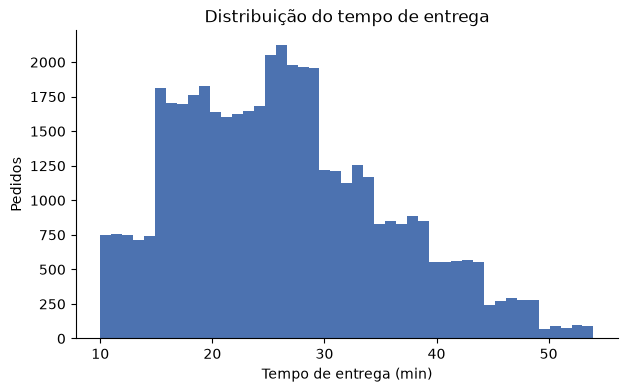

In [7]:
ax = dfc[TARGET].plot.hist(bins=45, color="#4C72B0")
ax.set(xlabel="Tempo de entrega (min)", ylabel="Pedidos", title="Distribuição do tempo de entrega")
plt.savefig("../reports/distribuicao_tempo.png", dpi=120, bbox_inches="tight")
dfc[TARGET].describe(percentiles=[0.1, 0.5, 0.9]).round(1)

### 5.2 Valores ausentes por coluna (após a limpeza)

In [8]:
(dfc.isna().mean().sort_values(ascending=False) * 100).round(1).loc[lambda s: s > 0].rename(
    "% ausente"
)

Restaurant_latitude            8.0
Restaurant_longitude           8.0
Delivery_location_longitude    8.0
distancia_km                   8.0
Delivery_location_latitude     8.0
Delivery_person_Ratings        4.3
Delivery_person_Age            4.1
Time_Orderd                    3.8
hora_pedido                    3.8
City                           2.6
multiple_deliveries            2.2
Weatherconditions              1.4
Road_traffic_density           1.3
Festival                       0.5
Name: % ausente, dtype: float64

### 5.3 Densidade de trânsito

,mean,median,count
Road_traffic_density,,,
Low,21.3,20.0,15477
Medium,26.7,27.0,10947
High,27.2,27.0,4425
Jam,31.2,31.0,14143


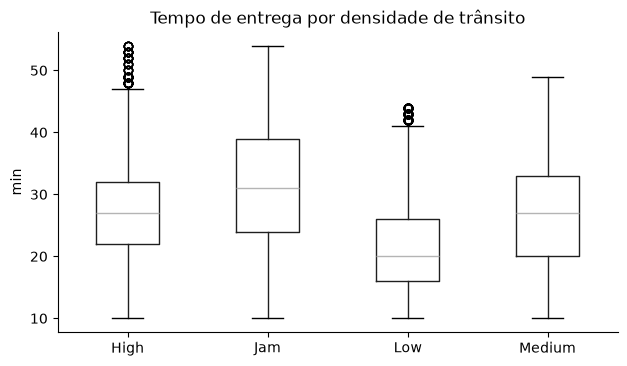

In [9]:
ordem = ["Low", "Medium", "High", "Jam"]
ax = dfc.boxplot(column=TARGET, by="Road_traffic_density", positions=None, grid=False)
plt.suptitle("")
ax.set(title="Tempo de entrega por densidade de trânsito", xlabel="", ylabel="min")
plt.savefig("../reports/tempo_por_transito.png", dpi=120, bbox_inches="tight")
dfc.groupby("Road_traffic_density")[TARGET].agg(["mean", "median", "count"]).reindex(ordem).round(1)

### 5.4 Condições climáticas

In [10]:
dfc.groupby("Weatherconditions")[TARGET].agg(["mean", "count"]).sort_values("mean").round(1)

,mean,count
Weatherconditions,,
Sunny,21.9,7284
Stormy,25.9,7586
Sandstorms,25.9,7495
Windy,26.1,7422
Fog,28.9,7654
Cloudy,28.9,7536


### 5.5 Entregas múltiplas

In [11]:
dfc.groupby("multiple_deliveries")[TARGET].agg(["mean", "count"]).round(1)

,mean,count
multiple_deliveries,,
0.0,22.9,14095
1.0,26.9,28159
2.0,40.5,1985
3.0,47.8,361


### 5.6 Festival e tipo de cidade

In [12]:
display(dfc.groupby("Festival")[TARGET].agg(["mean", "count"]).round(1))
dfc.groupby("City")[TARGET].agg(["mean", "count"]).round(1)

,mean,count
Festival,,
No,26.0,44469
Yes,45.5,896


,mean,count
City,,
Metropolitian,27.3,34093
Semi-Urban,49.7,164
Urban,23.0,10136


### 5.7 Distância

np.float64(0.321)

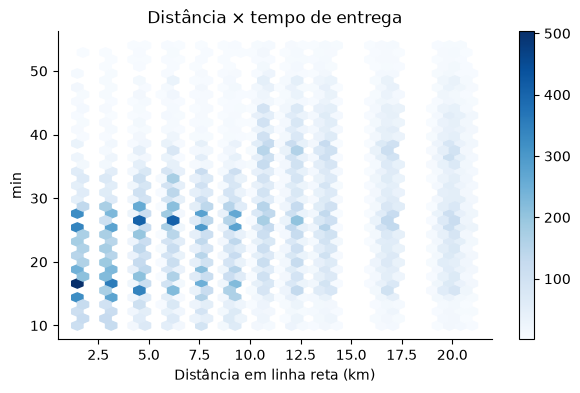

In [13]:
ax = dfc.plot.hexbin(x="distancia_km", y=TARGET, gridsize=35, cmap="Blues", mincnt=1)
ax.set(title="Distância × tempo de entrega", xlabel="Distância em linha reta (km)", ylabel="min")
plt.savefig("../reports/distancia_tempo.png", dpi=120, bbox_inches="tight")
dfc[["distancia_km", TARGET]].corr().iloc[0, 1].round(3)

### 5.8 Perfil do entregador

In [14]:
dfc[["Delivery_person_Age", "Delivery_person_Ratings", "Vehicle_condition", TARGET]].corr()[
    TARGET
].round(3)

Delivery_person_Age        0.299
Delivery_person_Ratings   -0.341
Vehicle_condition         -0.234
Time_taken(min)            1.000
Name: Time_taken(min), dtype: float64

In [15]:
dfc.groupby(pd.cut(dfc["Delivery_person_Ratings"], [0, 4, 4.5, 4.8, 5]), observed=True)[TARGET].agg(
    ["mean", "count"]
).round(1)

,mean,count
Delivery_person_Ratings,,
"(0.0, 4.0]",35.9,2444
"(4.0, 4.5]",30.6,8921
"(4.5, 4.8]",24.3,21230
"(4.8, 5.0]",24.6,11037


## 6. Riscos de vazamento

| Coluna | Disponível no momento do pedido? | Decisão |
|---|---|---|
| `Time_Order_picked` | **Não**: só existe depois que o entregador retira o pedido | **excluída** das features |
| `multiple_deliveries` | Só após a atribuição do entregador | mantida, assumindo ETA calculado na atribuição; impacto medido com e sem (ver README) |
| `Delivery_person_ID` | Sim, mas o modelo "decoraria" o entregador | não é feature; usada para **agrupar** a validação (`GroupKFold`) |

In [16]:
espera = (
    pd.to_datetime(dfc["Time_Order_picked"], format="%H:%M:%S", errors="coerce")
    - pd.to_datetime(dfc["Time_Orderd"], format="%H:%M:%S", errors="coerce")
).dt.total_seconds() / 60
espera.describe().round(1)

count    43862.0
mean       -17.3
std        196.1
min      -1435.0
25%          5.0
50%         10.0
75%         15.0
max         15.0
dtype: float64

Mediana de 10 min entre pedido e retirada (valores negativos são pedidos que cruzam a meia-noite). É uma informação forte, mas inexistente no momento do pedido: usá-la inflaria as métricas offline sem funcionar em produção.

## 7. Conclusões

- **Trânsito** é o fator categórico mais forte: com *Jam*, o tempo médio fica cerca de 10 minutos acima de *Low*.
- **Entregas múltiplas** e **festivais** aumentam bastante o tempo; o clima ensolarado é o mais rápido.
- A **nota do entregador** tem a correlação mais forte entre as numéricas (negativa): entregadores com nota abaixo de 4 são muito mais lentos.
- A **distância** importa (correlação ≈ 0,3), mas não explica o tempo sozinha: as interações com trânsito e perfil do entregador pedem um modelo não linear.
- ~16% dos pedidos têm algum ausente; descartá-los enviesaria a base (são entregas mais rápidas em média), então os ausentes são mantidos e tratados no pipeline.

## 8. Próximos passos

Limpeza → [`data.py`](../src/project_nov26_p1_eta/data.py) · Features → [`features.py`](../src/project_nov26_p1_eta/features.py) · Modelagem → [`scripts/train.py`](../scripts/train.py)